# Parte Específica: Visualização exploratória 1

**Variável:** `Total_Trans_Amt` (valor total transacionado em 12 meses, em US$), comparando clientes que
ficaram com clientes que cancelaram o cartão (`Attrition_Flag`).

**Tipo de gráfico:** boxplot, escolhido pelo grupo (Fernando).

> Foi escolhido o gráfico de boxplot utilizando as variáveis Total_Trans_Amt e Attrition_Flag. Essa visualização permite comparar a distribuição dos valores totais de transações entre clientes que permaneceram no banco e clientes que cancelaram o cartão. A escolha se justifica pela facilidade de visualizar as medianas, a dispersão e possíveis valores discrepantes, permitindo identificar diferenças no comportamento financeiro dos dois grupos.

In [1]:
# [IA] Claude Code – importacao das bibliotecas, leitura do dataset tratado e pasta de saida
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CAMINHO_DADOS = Path("../../out/parte_especifica/bankchurners_tratado.csv")
PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CAMINHO_DADOS)

In [2]:
# [IA] Claude Code – rotulos em portugues e cores fixas por grupo (as mesmas da visualizacao exploratoria 2)
ROTULOS_SITUACAO = {"Existing Customer": "Ficou", "Attrited Customer": "Cancelou"}
ORDEM_SITUACAO = ["Ficou", "Cancelou"]
CORES_SITUACAO = {"Ficou": "#4C72B0", "Cancelou": "#C44E52"}

df["Situacao"] = df["Attrition_Flag"].map(ROTULOS_SITUACAO)
assert df["Situacao"].notna().all()
df["Situacao"].value_counts().reindex(ORDEM_SITUACAO)

Situacao
Ficou       8500
Cancelou    1627
Name: count, dtype: int64

In [3]:
# [IA] Claude Code – numeros que acompanham o grafico: quartis, IQR e valores discrepantes (regra 1,5 x IQR) por grupo
def resumo_boxplot(serie):
    q1, mediana, q3 = serie.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    discrepantes = serie[(serie < lim_inf) | (serie > lim_sup)]
    return pd.Series({
        "qtd_clientes": len(serie),
        "minimo": serie.min(),
        "q1": q1,
        "mediana": mediana,
        "q3": q3,
        "maximo": serie.max(),
        "iqr": iqr,
        "limite_superior": lim_sup,
        "qtd_discrepantes": len(discrepantes),
        "pct_discrepantes": round(len(discrepantes) / len(serie) * 100, 2),
    })

resumo = (
    df.groupby("Situacao")["Total_Trans_Amt"]
    .apply(resumo_boxplot)
    .unstack()
    .reindex(ORDEM_SITUACAO)
    .round(1)
)
resumo

,qtd_clientes,minimo,q1,mediana,q3,maximo,iqr,limite_superior,qtd_discrepantes,pct_discrepantes
Situacao,,,,,,,,,,
Ficou,8500.0,816.0,2384.8,4100.0,4781.2,18484.0,2396.5,8376.0,849.0,10.0
Cancelou,1627.0,510.0,1903.5,2329.0,2772.0,10583.0,868.5,4074.8,315.0,19.4


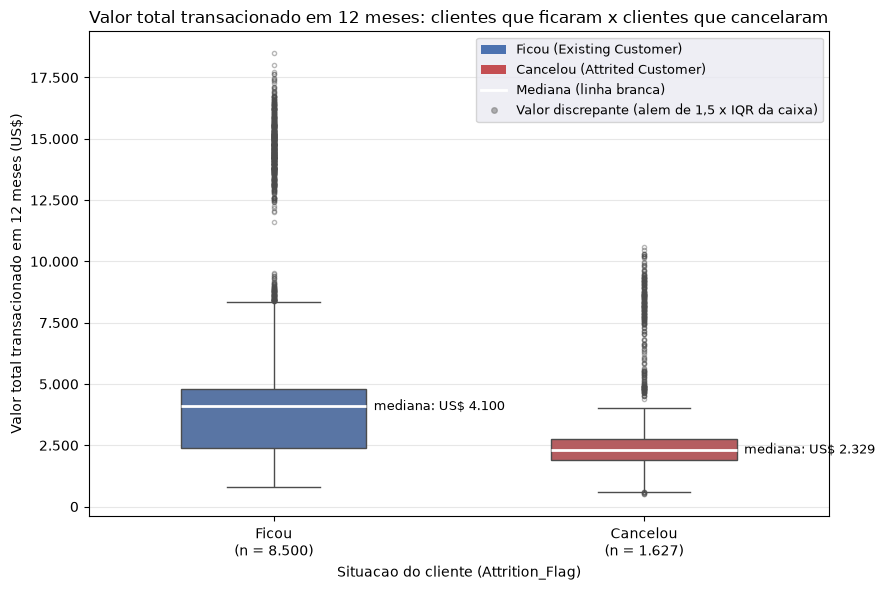

In [4]:
# [IA] Claude Code – boxplot de Total_Trans_Amt por situacao do cliente
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=df, x="Situacao", y="Total_Trans_Amt",
    hue="Situacao", order=ORDEM_SITUACAO, palette=CORES_SITUACAO, legend=False,
    width=0.5,
    whis=1.5,   # bigodes ate 1,5 x IQR; pontos alem disso sao os valores discrepantes
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.4},
    medianprops={"color": "white", "linewidth": 2},
    ax=ax,
)

# Quantidade de clientes de cada grupo no rotulo do eixo x
qtd = df["Situacao"].value_counts()
ax.set_xticks(range(len(ORDEM_SITUACAO)))
ax.set_xticklabels([f"{s}\n(n = {qtd[s]:,})".replace(",", ".") for s in ORDEM_SITUACAO])

# Valor da mediana escrito ao lado de cada caixa
for i, situacao in enumerate(ORDEM_SITUACAO):
    mediana = resumo.loc[situacao, "mediana"]
    ax.annotate(f"mediana: US$ {mediana:,.0f}".replace(",", "."), xy=(i + 0.27, mediana),
                va="center", fontsize=9)

# Legenda: cores dos grupos e elementos do boxplot
legenda = [
    Patch(facecolor=CORES_SITUACAO["Ficou"], label="Ficou (Existing Customer)"),
    Patch(facecolor=CORES_SITUACAO["Cancelou"], label="Cancelou (Attrited Customer)"),
    Line2D([0], [0], color="white", linewidth=2, label="Mediana (linha branca)"),
    Line2D([0], [0], marker="o", color="gray", linestyle="", markersize=4, alpha=0.6,
           label="Valor discrepante (alem de 1,5 x IQR da caixa)"),
]
ax.legend(handles=legenda, loc="upper right", fontsize=9, facecolor="#EAEAF2")

ax.set_title("Valor total transacionado em 12 meses: clientes que ficaram x clientes que cancelaram")
ax.set_xlabel("Situacao do cliente (Attrition_Flag)")
ax.set_ylabel("Valor total transacionado em 12 meses (US$)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(PASTA_SAIDA / "viz_exploratoria_1_boxplot_trans_amt.png", dpi=150, bbox_inches="tight")
plt.show()

## Nota analítica

**O que está sendo mostrado:** O gráfico apresenta uma comparação da distribuição do valor total de transações realizadas pelos clientes nos últimos 12 meses (Total_Trans_Amt), separando aqueles que permaneceram no banco daqueles que cancelaram o cartão (Attrition_Flag). São apresentados a mediana, os quartis, a dispersão dos valores e possíveis pontos discrepantes de cada grupo.

**Qual insight pode ser extraído:** É possível observar que os clientes que permaneceram no banco apresentam uma mediana de transações de US$ 4.100, enquanto os clientes que cancelaram possuem uma mediana de US$ 2.329. Essa diferença indica que os clientes que cancelaram o cartão apresentavam, em geral, menor volume de transações financeiras. Isso sugere uma associação entre menor utilização do cartão e maior ocorrência de cancelamentos.

**Por que este tipo de visualização foi escolhido:** Foi escolhido o gráfico de boxplot utilizando as variáveis Total_Trans_Amt e Attrition_Flag. Essa visualização permite comparar a distribuição dos valores totais de transações entre clientes que permaneceram no banco e clientes que cancelaram o cartão. A escolha se justifica pela facilidade de visualizar as medianas, a dispersão e possíveis valores discrepantes, permitindo identificar diferenças no comportamento financeiro dos dois grupos.